# Лабораторная работа 2. Сегментация потребителей леденцов

## Цель и постановка задачи

По ответам респондентов необходимо определить число кластеров,
выполнить кластеризацию методом k-means по мотивам потребления
и содержательно объяснить группы. Дополнительно рассмотрим результат DBSCAN.

## 1. Данные

Каждая строка представляет одного респондента, каждый столбец - оценку согласия
с высказыванием о цели потребления леденцов. Предполагаем, что большая оценка
означает более сильное согласие.

| Признак | Мотив потребления |
|---|---|
| V1 | Освежить дыхание |
| V2 | Чувствовать себя увереннее |
| V3 | Освежить полость рта |
| V4 | Избавиться от неприятного вкуса во рту |
| V5 | Заменить другие кондитерские изделия |
| V6 | Удовлетворить желание сладкого |
| V7 | Сконцентрироваться |
| V8 | Отвлечься на несколько минут и подумать |
| V9 | Облегчить боль в горле |
| V10 | Избавиться от заложенности носа |
| V11 | Улучшить самочувствие |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.manifold import MDS

df = pd.read_csv("Леденцы.dat", sep=";")

display(df.head())
print("Размер данных:", df.shape)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


Размер данных: (338, 11)


Для кластеризации используем признаки V1–V11. Проверим, что они содержат
числовые оценки без пропусков, и рассмотрим описательные статистики.

In [2]:
X = df[[f"V{i}" for i in range(1, 12)]].copy()

print("Количество пропусков:", X.isna().sum().sum())
print("Типы данных:")
print(X.dtypes)

display(X.describe())

Количество пропусков: 0
Типы данных:
V1     int64
V2     int64
V3     int64
V4     int64
V5     int64
V6     int64
V7     int64
V8     int64
V9     int64
V10    int64
V11    int64
dtype: object


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


В файле 338 респондентов и 11 числовых признаков, пропуски
отсутствуют. Наблюдаемые оценки лежат в диапазоне 2–5.
Совпадающие строки не удаляем, поскольку одинаковые ответы могли дать разные
люди. Удаление таких строк изменило бы веса наблюдений и доли сегментов.

## 2. Подготовка и выбор метода

Все признаки измерены одной шкалой, а выборочные стандартные отклонения близки
(примерно 0,82–0,99). Поэтому анализ выполняется на исходных оценках.
При этом считаем интервалы между соседними баллами приблизительно одинаковыми.

Используем метод k-means. Сначала выбираются начальные центры, затем каждый
объект относится к ближайшему центру по евклидову расстоянию. Центры
пересчитываются как средние по полученным группам, и эти шаги повторяются
до выполнения условия остановки. Метод минимизирует внутрикластерную сумму
квадратов:

$$WCSS=\sum_{j=1}^{k}\sum_{x_i\in C_j}\|x_i-\mu_j\|^2,$$

где $C_j$ — кластер, а $\mu_j$ — его центр.

Метод подходит для поиска компактных групп с различными средними профилями.
Число кластеров задаётся заранее, поэтому сравним несколько вариантов.
Для каждого используем 20 запусков (`n_init=20`) и выбираем результат
с минимальной WCSS. Параметр `random_state=42` фиксирует случайность
в используемой программной среде.

## 3. Предварительный выбор числа кластеров

### Правило локтя

Для каждого числа кластеров от 2 до 10 вычисляем WCSS — сумму квадратов
расстояний от объектов до центров своих кластеров. Ищем точку, после которой
добавление новых групп даёт заметно меньший выигрыш. В отличие от иерархического
метода, для каждого значения $k$ модель обучается заново.

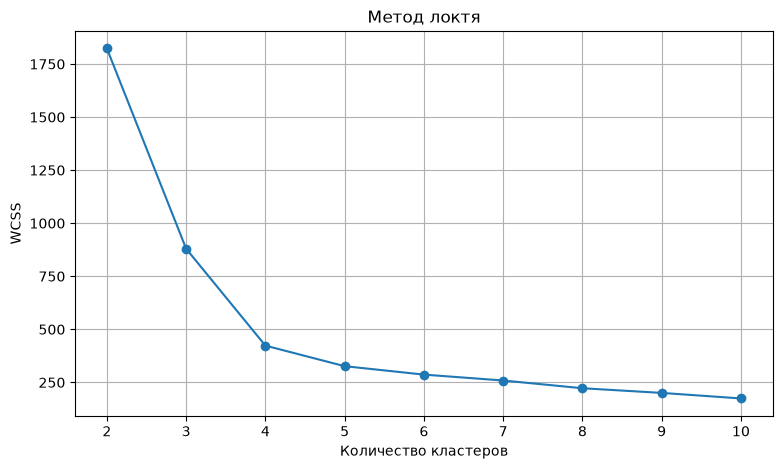

In [3]:
k_values = range(2, 11)
wcss = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    model.fit(X)
    wcss.append(model.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(k_values, wcss, marker="o")
plt.xlabel("Количество кластеров")
plt.ylabel("WCSS")
plt.title("Метод локтя")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

Значения WCSS для 2, 3, 4 и 5 кластеров составляют соответственно
1823,30; 879,72; 423,14 и 326,25. Несложно заметить, что после четырёх
кластеров уменьшение становится существенно менее выраженным: на графике
формируется «локоть» около $k=4$.

Однако визуального выбора недостаточно, поэтому проверим его дополнительным
критерием.

### Дополнительная проверка коэффициентом силуэта

Коэффициент силуэта оценивает одновременно компактность кластеров и их отделённость
друг от друга. Для каждого объекта он определяется как

$$s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))},$$

где $a(i)$ — среднее расстояние до остальных объектов своего кластера,
а $b(i)$ — наименьшее среднее расстояние до объектов другого кластера.
Значение близкое к 1 означает хорошее соответствие объекта своему кластеру,
около 0 — положение на границе, отрицательное — возможное ошибочное отнесение.

Ниже сравнивается средний коэффициент силуэта для решений от 2 до 10 кластеров.
Итоговый выбор также должен учитывать размеры групп и возможность
их содержательной интерпретации.

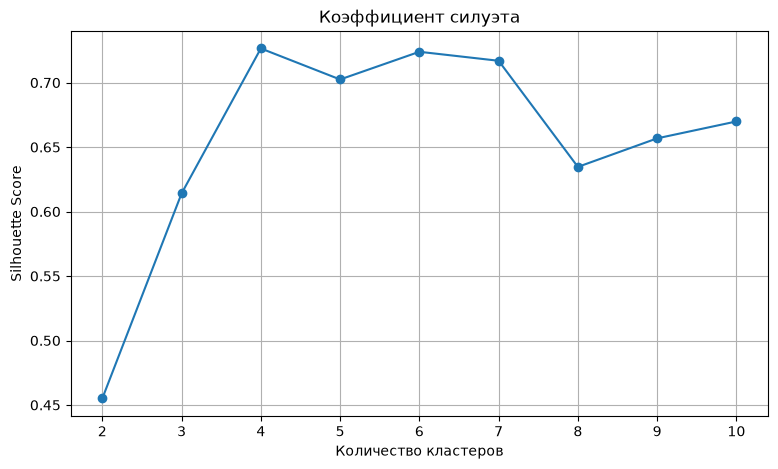

Лучшее k по силуэту: 4


In [4]:
scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X)
    scores.append(silhouette_score(X, labels))

plt.figure(figsize=(9, 5))
plt.plot(range(2, 11), scores, marker="o")
plt.xlabel("Количество кластеров")
plt.ylabel("Silhouette Score")
plt.title("Коэффициент силуэта")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

print("Лучшее k по силуэту:", np.argmax(scores) + 2)

### Итоговый выбор числа кластеров

На графике WCSS заметен локоть около четырёх групп. Среди проверенных
вариантов k-means максимальный силуэт также достигается при $k=4$ и равен
примерно 0,7265. При $k=3$ он составляет 0,6140, при $k=5$ — 0,7024.
Поэтому именно четыре выберем как итоговое число кластеров.

Выборка при этом разбивается на достаточно крупные группы, имеющие
содержательную интерпретацию, что будет показано ниже.

In [5]:
k = 4

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=20
)

df["cluster"] = kmeans.fit_predict(X) + 1

print("Количество респондентов в кластерах:")
print(df["cluster"].value_counts().sort_index())

print("\nWCSS:", kmeans.inertia_)
print("Silhouette Score:", silhouette_score(X, df["cluster"]))

Количество респондентов в кластерах:
cluster
1    108
2     61
3    110
4     59
Name: count, dtype: int64

WCSS: 423.1440507698085
Silhouette Score: 0.7265095702205504


Для интерпретации рассмотрим средние оценки V1–V11 в каждой группе.
Они соответствуют координатам центроидов k-means. Тепловая карта позволяет
увидеть, какие мотивы выражены сильнее всего.

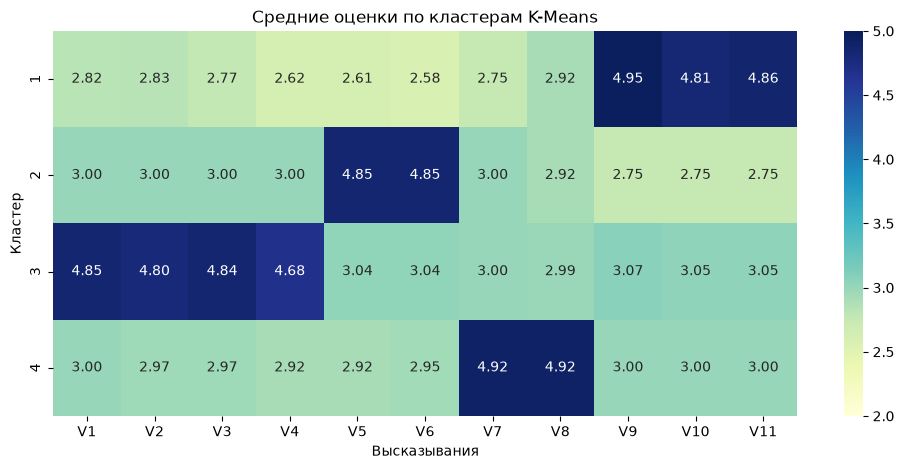

In [6]:
profile = df.groupby("cluster")[X.columns].mean()

plt.figure(figsize=(12, 5))

sns.heatmap(
    profile,
    annot=True,
    cmap="YlGnBu",
    vmin=2,
    vmax=5,
    fmt=".2f"
)

plt.title("Средние оценки по кластерам K-Means")
plt.xlabel("Высказывания")
plt.ylabel("Кластер")
plt.show()

### Содержательная интерпретация четырёх групп

| Кластер | Человек | Доля выборки | Условное название | Основание |
|---|---:|---:|---|---|
| 1 | 108 | 31,95% | Облегчение дискомфорта | V9=4,95; V10=4,81; V11=4,86 |
| 2 | 61 | 18,05% | Сладкоежки | V5=4,85; V6=4,85 |
| 3 | 110 | 32,54% | Уверенность | V1=4,85; V2=4,80; V3=4,84; V4=4,68 |
| 4 | 59 | 17,46% | Концентрация | V7=4,92; V8=4,92 |

**Кластер 1. Облегчение дискомфорта.** Леденцы прежде всего
ассоциируются с облегчением боли в горле, заложенности носа и улучшением
самочувствия. Остальные средние оценки ниже 3.

**Кластер 2. Сладкоежки.** Леденцы рассматриваются как сладость
и альтернатива другим кондитерским изделиям.

**Кластер 3. Уверенность.** Устранение неприятного вкуса во рту, свежесть
дыхания и полости рта сочетаются с желанием чувствовать себя увереннее.
Остальные мотивы имеют средние оценки около 3. В выборке это самый большой сегмент.

**Кластер 4. Концентрация.** Высокие оценки V7–V8 показывают
связь потребления с сосредоточением и возможностью ненадолго отвлечься и подумать.
Другие мотивы выражены слабее. Утверждать по этим данным, что участники являются
студентами или офисными работниками, нельзя: таких признаков нет.

Названия описывают различия средних профилей, а не каждого участника без исключения.
Все четыре сегмента достаточно заметны в данной выборке: минимальный содержит
59 человек, или 17,46%. Это не оценка долей всего рынка.

## 4. Визуализация кластеров

Для изображения данных на плоскости используем метод главных компонент (PCA).
Первые две компоненты сохраняют примерно 77,98% общей дисперсии.
Цветом обозначены группы k-means, чёрными крестиками — проекции их центроидов.
Кластеризация выполнена по всем 11 признакам; рисунок служит для визуализации
и не передаёт все расстояния исходного пространства.

C:\Users\1\Documents\ChatGPT\бд\.venv-lab\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


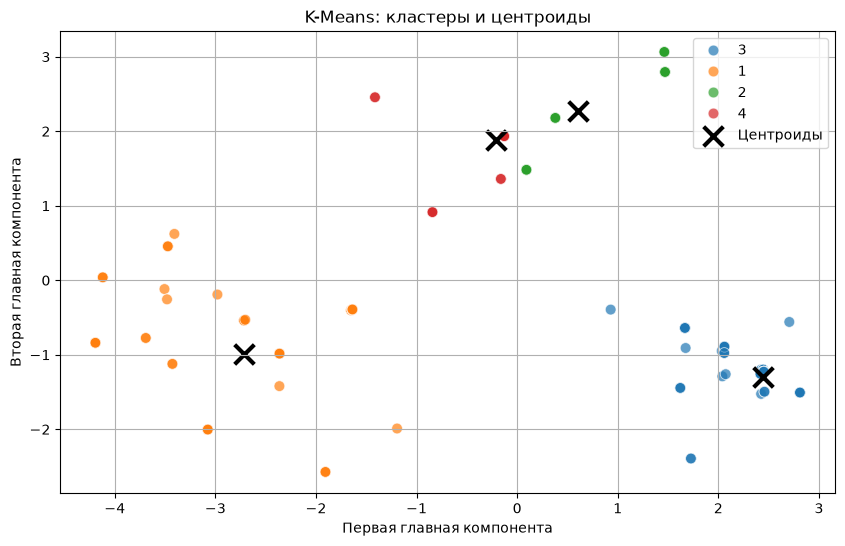

In [7]:
from sklearn.decomposition import PCA

# PCA для двумерной визуализации
pca = PCA(n_components=2)

X_2d = pca.fit_transform(X)
centers_2d = pca.transform(kmeans.cluster_centers_)

df_plot = pd.DataFrame(X_2d, columns=["PC1", "PC2"])
df_plot["cluster"] = (kmeans.labels_ + 1).astype(str)

plt.figure(figsize=(10, 6))

# Респонденты
sns.scatterplot(
    data=df_plot,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    s=60,
    alpha=0.7
)

# Центроиды — обязательно чёрные крестики
plt.scatter(
    centers_2d[:, 0],
    centers_2d[:, 1],
    c="black",
    marker="x",
    s=200,
    linewidths=3,
    label="Центроиды"
)

plt.title("K-Means: кластеры и центроиды")
plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.legend()
plt.grid(True)
plt.show()

## 5. Сравнение компактности групп

Для каждого объекта вычислим евклидово расстояние до центра своего кластера,
затем усредним эти расстояния внутри каждой группы:

$$\bar d_j=\frac{1}{n_j}\sum_{x_i\in C_j}\|x_i-\mu_j\|.$$

Чем меньше среднее расстояние, тем компактнее группа. Здесь используются
обычные расстояния, а в WCSS — их квадраты. Несмотря на название переменной
`density`, рассчитываемый показатель характеризует компактность, а не плотность.

In [8]:
# Евклидово расстояние до центроида своего кластера
labels = kmeans.labels_
centers = kmeans.cluster_centers_

distances = np.linalg.norm(
    X.to_numpy() - centers[labels],
    axis=1
)

# Среднее расстояние для каждого кластера
density = pd.DataFrame({
    "cluster": labels + 1,
    "distance": distances
})

cluster_stats = density.groupby("cluster").agg(
    count=("distance", "size"),
    mean_distance=("distance", "mean")
)

display(cluster_stats)

print("Общее среднее расстояние:", distances.mean())

,count,mean_distance
cluster,,
1,108,1.385038
2,61,0.830196
3,110,0.849202
4,59,0.374534


Общее среднее расстояние: 0.9341296111740245


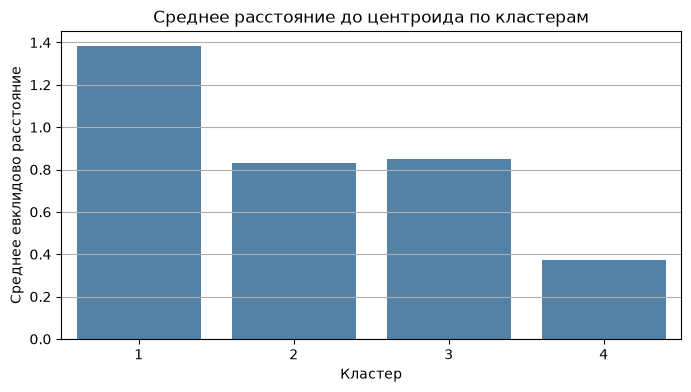

In [9]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=cluster_stats.reset_index(),
    x="cluster",
    y="mean_distance",
    color="steelblue"
)

plt.title("Среднее расстояние до центроида по кластерам")
plt.xlabel("Кластер")
plt.ylabel("Среднее евклидово расстояние")
plt.grid(axis="y")
plt.show()

Средние расстояния до центров составляют 1,385; 0,830; 0,849 и 0,375
для кластеров 1–4 соответственно. Наиболее компактна группа «Концентрация»,
наибольший разброс наблюдается в группе «Облегчение дискомфорта».
Среднее расстояние по всей выборке равно 0,934.

## 6. Дополнительная кластеризация методом DBSCAN

DBSCAN выделяет связанные плотные области и может оставлять отдельные
наблюдения шумом. В отличие от k-means число кластеров заранее не задаётся.
Параметр `eps` определяет радиус окрестности, а `min_samples` — минимальное
число объектов в ней, включая сам объект, необходимое для образования ядра.

В этом разделе признаки стандартизируются, поэтому расстояния и `eps`
относятся к стандартизированным данным. Для выбора радиуса рассмотрим график
расстояний до соседей при `min_samples=12`. В данном расчёте сам объект
входит в число 12 соседей.

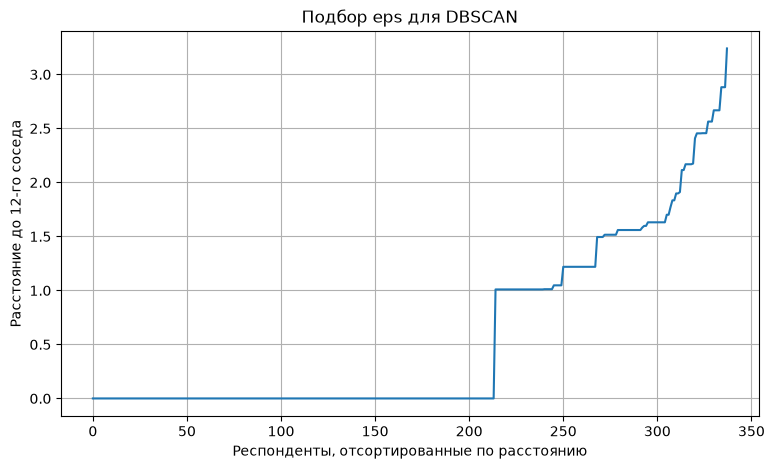

In [10]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

X = df[[f"V{i}" for i in range(1, 12)]].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

min_samples = 12

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_distances)

plt.xlabel("Респонденты, отсортированные по расстоянию")
plt.ylabel("Расстояние до 12-го соседа")
plt.title("Подбор eps для DBSCAN")
plt.grid(True)
plt.show()

### Выбор параметров DBSCAN

На правой части графика расстояния начинают расти быстрее.
В качестве пробного радиуса используем `eps=2`, при `min_samples=12`.
График служит ориентиром, но сам по себе не доказывает оптимальность параметров.
Метка −1 обозначает шум, остальные метки — найденные группы.

In [11]:
dbscan = DBSCAN(
    eps=2,
    min_samples=12,
    metric="euclidean"
)

labels = dbscan.fit_predict(X_scaled)

df["cluster_dbscan"] = labels

n_clusters = len(set(labels) - {-1})
n_noise = np.sum(labels == -1)

print("Количество кластеров:", n_clusters)
print("Количество шумовых точек:", n_noise)

print(df["cluster_dbscan"].value_counts().sort_index())

Количество кластеров: 4
Количество шумовых точек: 10
cluster_dbscan
-1     10
 0    110
 1    100
 2     61
 3     57
Name: count, dtype: int64


### Дополнительная проверка коэффициентом силуэта

DBSCAN выделил четыре кластера и отнёс 10 наблюдений к шуму.
Рассчитаем силуэт только для объектов, попавших в кластеры, и отдельно
укажем долю шумовых точек.

In [12]:
mask = labels != -1

if len(set(labels[mask])) >= 2:
    score = silhouette_score(X_scaled[mask], labels[mask])
    print("Silhouette Score:", score)
else:
    print("Недостаточно кластеров для расчёта силуэта")
print(f"Доля шума: {n_noise / len(labels):.2%}")

Silhouette Score: 0.7503946950419316
Доля шума: 2.96%


Силуэт равен 0,7504, доля шума — 2,96%. Прямое сравнение этого силуэта
с результатом k-means некорректно: DBSCAN оценён на стандартизированных данных
и без 10 шумовых объектов, а k-means — на исходных оценках всей выборки.

### Визуализация результата DBSCAN

Для изображения групп снова используем PCA, теперь по стандартизированным данным.
Первые две компоненты сохраняют примерно 75,21% дисперсии.
Серым отмечены шумовые точки. Шумовая метка не означает ошибку в исходной записи.

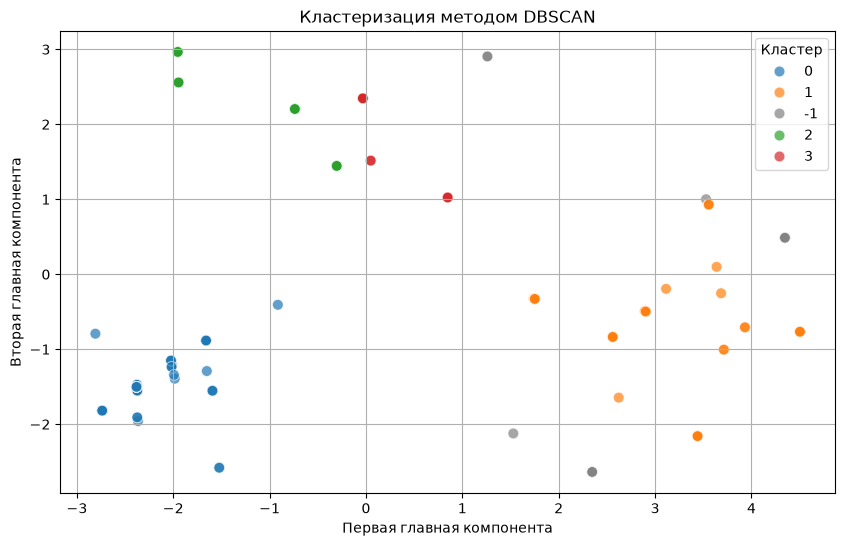

In [13]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

df_plot = pd.DataFrame(X_2d, columns=["PC1", "PC2"])
df_plot["cluster"] = labels.astype(str)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_plot,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette={
        str(c): "gray" if c == -1 else sns.color_palette("tab10")[c % 10]
        for c in np.unique(labels)
    },
    s=60,
    alpha=0.7
)

plt.title("Кластеризация методом DBSCAN")
plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.legend(title="Кластер")
plt.grid(True)
plt.show()

### Содержательная интерпретация групп DBSCAN

Рассмотрим средние исходные оценки внутри найденных кластеров.
Шумовые точки не включаем. Номера групп DBSCAN условны и отличаются
от номеров k-means.

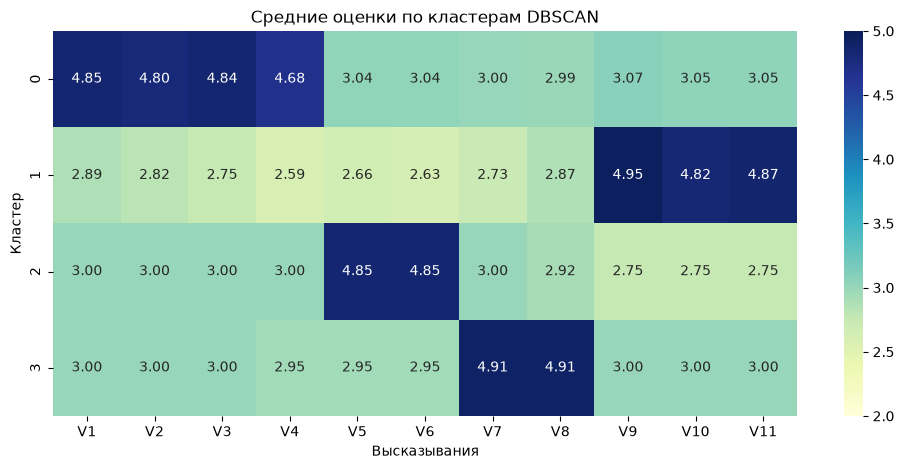

In [14]:
profile = (
    df[df["cluster_dbscan"] != -1]
    .groupby("cluster_dbscan")[X.columns]
    .mean()
)

if not profile.empty:
    plt.figure(figsize=(12, 5))

    sns.heatmap(
        profile,
        annot=True,
        cmap="YlGnBu",
        vmin=2,
        vmax=5,
        fmt=".2f"
    )

    plt.title("Средние оценки по кластерам DBSCAN")
    plt.xlabel("Высказывания")
    plt.ylabel("Кластер")
    plt.show()
else:
    print("DBSCAN не выделил кластеров")

| Кластер DBSCAN | Человек | Условное название | Основание |
|---|---:|---|---|
| 0 | 110 | Уверенность | Высокие оценки V1–V4 |
| 1 | 100 | Облегчение дискомфорта | Высокие оценки V9–V11 |
| 2 | 61 | Сладкоежки | Высокие оценки V5–V6 |
| 3 | 57 | Концентрация | Высокие оценки V7–V8 |

Содержательно выделяются те же четыре блока мотивов. Группы «Уверенность»
и «Сладкоежки» сохранили свой состав. Из групп «Облегчение дискомфорта»
и «Концентрация» к шуму отнесены соответственно 8 и 2 респондента.

## 7. Выводы

Методом k-means выделены четыре группы потребителей леденцов: «Облегчение
дискомфорта», «Сладкоежки», «Уверенность» и «Концентрация».
Выбор числа кластеров поддерживают правило локтя и максимальный силуэт
среди проверенных вариантов от 2 до 10. Итоговая WCSS составляет 423,14,
силуэт — 0,7265.

Самая большая группа — «Уверенность»: 110 человек, или 32,54% выборки.
Наиболее компактны ответы группы «Концентрация». Дополнительный анализ
методом DBSCAN также выделяет четыре содержательно сходные группы,
оставляя 10 наблюдений шумом. В качестве основного результата используем
разбиение k-means, охватывающее всех респондентов.